# Step 1: Missing Values and Missing Timestamps

## Setup & Load Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

energy = pd.read_csv("../data/raw/energy_dataset.csv")
weather = pd.read_csv("../data/raw/weather_features.csv")

# keep raw copies, we don't change the originals
energy_raw = energy.copy()
weather_raw = weather.copy()

# timestamps -> UTC
energy["time"] = pd.to_datetime(energy["time"], utc=True)
weather["dt_iso"] = pd.to_datetime(weather["dt_iso"], utc=True)

energy = energy.sort_values("time").set_index("time")
print("Energy:", energy.shape, "| Weather:", weather.shape)

Energy: (35064, 28) | Weather: (178396, 17)


## Missing Timestamps: Energy

In [3]:
full_range = pd.date_range(energy.index.min(), energy.index.max(), freq="h")
missing_ts = full_range.difference(energy.index)

print("Expected hours:", len(full_range))
print("Rows in energy:", len(energy))
print("Missing timestamps:", len(missing_ts))

Expected hours: 35064
Rows in energy: 35064
Missing timestamps: 0


## Missing Timestamps: Weather (per city)

In [4]:
for city, g in weather.groupby("city_name"):
    hours = pd.DatetimeIndex(g["dt_iso"].drop_duplicates())
    missing = full_range.difference(hours)
    print(f"{city:>10} | rows={len(g)} | unique hours={len(hours)} | missing hours={len(missing)}")

 Barcelona | rows=35476 | unique hours=35064 | missing hours=0
    Bilbao | rows=35951 | unique hours=35064 | missing hours=0
    Madrid | rows=36267 | unique hours=35064 | missing hours=0
   Seville | rows=35557 | unique hours=35064 | missing hours=0
  Valencia | rows=35145 | unique hours=35064 | missing hours=0


## Missing Values: Energy

In [5]:
na = energy.isna().sum()
na = na[na > 0].sort_values(ascending=False)

pd.DataFrame({"missing": na, "pct": (na / len(energy) * 100).round(3)})

,missing,pct
generation hydro pumped storage aggregated,35064,100.000
forecast wind offshore eday ahead,35064,100.000
total load actual,36,0.103
generation waste,19,0.054
generation marine,19,0.054
generation hydro pumped storage consumption,19,0.054
generation biomass,19,0.054
generation fossil oil,19,0.054
generation hydro run-of-river and poundage,19,0.054
generation fossil peat,18,0.051


## Missing Values: Weather

In [6]:
print("Total missing values in weather:", weather.isna().sum().sum())

Total missing values in weather: 0


## Gap Locations and Lengths

In [7]:
def find_gaps(series):
    miss = series.isna()                         # True = this hour is missing
    block = (miss != miss.shift()).cumsum()      # number each consecutive block
    return (series.index.to_series()[miss]
            .groupby(block[miss])
            .agg(start="first", end="last", hours="count"))

In [8]:
demand_gaps = find_gaps(energy["total load actual"])
print("Number of gaps:", len(demand_gaps))
print(demand_gaps["hours"].value_counts().sort_index())
demand_gaps

Number of gaps: 22
hours
1    19
3     1
6     1
8     1
Name: count, dtype: int64


,start,end,hours
total load actual,,,
2,2015-01-05 11:00:00+00:00,2015-01-05 16:00:00+00:00,6
4,2015-01-28 12:00:00+00:00,2015-01-28 12:00:00+00:00,1
6,2015-02-01 06:00:00+00:00,2015-02-01 08:00:00+00:00,3
8,2015-02-01 11:00:00+00:00,2015-02-01 18:00:00+00:00,8
10,2015-04-05 01:00:00+00:00,2015-04-05 01:00:00+00:00,1
12,2015-04-16 07:00:00+00:00,2015-04-16 07:00:00+00:00,1
14,2015-04-20 06:00:00+00:00,2015-04-20 06:00:00+00:00,1
16,2015-04-23 19:00:00+00:00,2015-04-23 19:00:00+00:00,1
18,2015-05-02 08:00:00+00:00,2015-05-02 08:00:00+00:00,1


In [9]:
# generation columns that are not completely empty
gen_cols = [c for c in energy.columns
            if c.startswith("generation") and energy[c].notna().any()]

# NaN if ANY generation column is missing in that hour
gen_check = energy[gen_cols].sum(axis=1, min_count=len(gen_cols))

gen_gaps = find_gaps(gen_check)
print("Number of gaps:", len(gen_gaps))
print(gen_gaps["hours"].value_counts().sort_index())
gen_gaps

Number of gaps: 18
hours
1    16
2     1
6     1
Name: count, dtype: int64


,start,end,hours
2,2015-01-05 02:00:00+00:00,2015-01-05 02:00:00+00:00,1
4,2015-01-05 11:00:00+00:00,2015-01-05 16:00:00+00:00,6
6,2015-01-19 18:00:00+00:00,2015-01-19 19:00:00+00:00,2
8,2015-01-27 18:00:00+00:00,2015-01-27 18:00:00+00:00,1
10,2015-01-28 12:00:00+00:00,2015-01-28 12:00:00+00:00,1
12,2015-04-16 07:00:00+00:00,2015-04-16 07:00:00+00:00,1
14,2015-04-23 19:00:00+00:00,2015-04-23 19:00:00+00:00,1
16,2015-06-15 07:00:00+00:00,2015-06-15 07:00:00+00:00,1
18,2015-10-02 09:00:00+00:00,2015-10-02 09:00:00+00:00,1
20,2015-12-02 08:00:00+00:00,2015-12-02 08:00:00+00:00,1


In [10]:
# Demand gaps per year (how many gaps, how many missing hours)
print(demand_gaps.groupby(demand_gaps["start"].dt.year)["hours"].agg(["count", "sum"]))

# Generation gaps per year
print(gen_gaps.groupby(gen_gaps["start"].dt.year)["hours"].agg(["count", "sum"]))

       count  sum
start            
2015      13   27
2016       5    5
2017       2    2
2018       2    2
       count  sum
start            
2015      10   16
2016       7    7
2018       1    1


In [11]:
# Are any missing hours on the first day of the year (Jan 1)?
# Local Spain time is used, because Jan 1 00:00 local is Dec 31 23:00 UTC
def gap_dates(gaps):
    out = gaps.copy()
    local = out["start"].dt.tz_convert("Europe/Madrid")
    out["local_start"] = local
    out["day_of_year"] = local.dt.dayofyear
    out["first_day_of_year"] = out["day_of_year"] == 1
    return out

for name, gaps in [("Demand", demand_gaps), ("Generation", gen_gaps)]:
    g = gap_dates(gaps)
    print(f"{name} gaps on Jan 1:", g["first_day_of_year"].sum())
    print(g[["local_start", "hours", "day_of_year"]].sort_values("day_of_year").to_string())

    print()

Demand gaps on Jan 1: 0
                                local_start  hours  day_of_year
total load actual                                              
2                 2015-01-05 12:00:00+01:00      6            5
4                 2015-01-28 13:00:00+01:00      1           28
6                 2015-02-01 07:00:00+01:00      3           32
8                 2015-02-01 12:00:00+01:00      8           32
10                2015-04-05 03:00:00+02:00      1           95
12                2015-04-16 09:00:00+02:00      1          106
14                2015-04-20 08:00:00+02:00      1          110
16                2015-04-23 21:00:00+02:00      1          113
28                2016-04-25 05:00:00+02:00      1          116
30                2016-04-25 07:00:00+02:00      1          116
18                2015-05-02 10:00:00+02:00      1          122
32                2016-05-10 23:00:00+02:00      1          131
20                2015-05-29 03:00:00+02:00      1          149
42              

In [12]:
demand_gaps[demand_gaps["hours"] >= 3]

,start,end,hours
total load actual,,,
2,2015-01-05 11:00:00+00:00,2015-01-05 16:00:00+00:00,6
6,2015-02-01 06:00:00+00:00,2015-02-01 08:00:00+00:00,3
8,2015-02-01 11:00:00+00:00,2015-02-01 18:00:00+00:00,8


# Step 2: Duplicate timestamps or more than one row for the same time.


## Duplicate Timestamps: Energy

In [13]:
print("Duplicate timestamps in energy:", energy.index.duplicated().sum())

Duplicate timestamps in energy: 0


## Duplicate Rows: Weather (same city + same hour)

In [14]:
key = ["city_name", "dt_iso"]
dup_mask = weather.duplicated(subset=key, keep=False)

print("Extra duplicate rows:", weather.duplicated(subset=key).sum())
print("Rows involved in duplicates:", dup_mask.sum())
print("Duplicate keys (city + hour):", weather[dup_mask].groupby(key).ngroups)
print()
print(weather[weather.duplicated(subset=key)]["city_name"].value_counts())

Extra duplicate rows: 3076
Rows involved in duplicates: 5874
Duplicate keys (city + hour): 2798

city_name
Madrid        1203
Bilbao         887
Seville        493
 Barcelona     412
Valencia        81
Name: count, dtype: int64


## Are the Duplicates Identical or Conflicting?

In [15]:
dups = weather[dup_mask]

num_cols = ["temp", "temp_min", "temp_max", "pressure", "humidity",
            "wind_speed", "wind_deg", "rain_1h", "rain_3h", "snow_3h", "clouds_all"]
text_cols = ["weather_id", "weather_main", "weather_description", "weather_icon"]

num_conflicts = (dups.groupby(key)[num_cols].nunique().max(axis=1) > 1).sum()
text_conflicts = (dups.groupby(key)[text_cols].nunique().max(axis=1) > 1).sum()

print("Keys with different numeric values:", num_conflicts)
print("Keys with different text values:", text_conflicts)
print("Exact full-row copies:", weather.duplicated().sum())

Keys with different numeric values: 0
Keys with different text values: 2777
Exact full-row copies: 21


## Example of One Duplicated Hour

In [16]:
dups.sort_values(key).head(6)

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
109256,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,500,rain,light rain,10n
109257,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,301,drizzle,drizzle,09n
111170,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,503,rain,very heavy rain,10d
111171,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d
111172,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,502,rain,heavy intensity rain,10d
111173,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d


## City Names Check

In [17]:
print([repr(c) for c in weather["city_name"].unique()])

["'Valencia'", "'Madrid'", "'Bilbao'", "' Barcelona'", "'Seville'"]


# Step 3: Values that are impossible or outside expected ranges.

## Temporary Copy of Weather (no duplicates)

In [18]:
# temporary copy for plotting only, the original weather table is not changed
wd = weather.drop_duplicates(["city_name", "dt_iso"])

## Boxplots: Energy

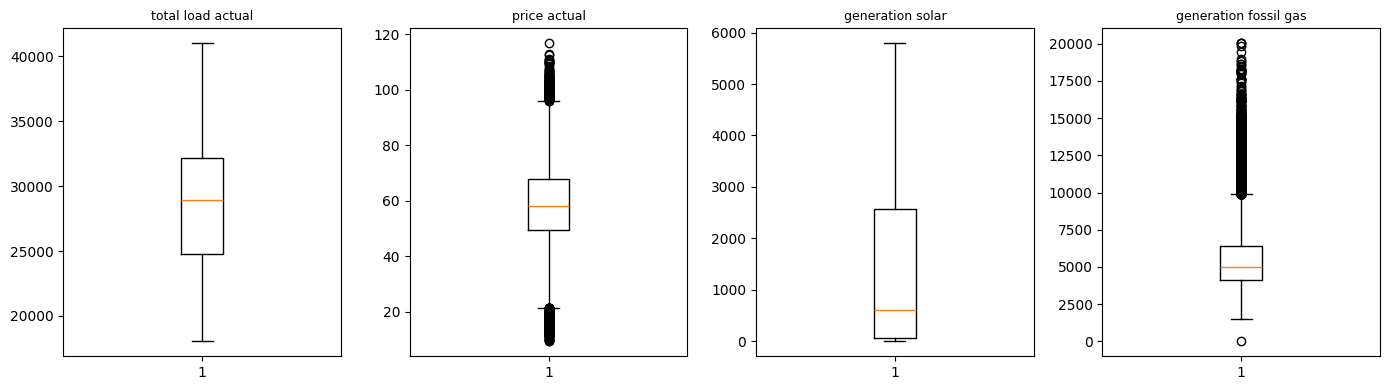

In [19]:
cols = ["total load actual", "price actual", "generation solar", "generation fossil gas"]

fig, axes = plt.subplots(1, len(cols), figsize=(14, 4))
for ax, c in zip(axes, cols):
    ax.boxplot(energy[c].dropna())
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

## Boxplots: Weather

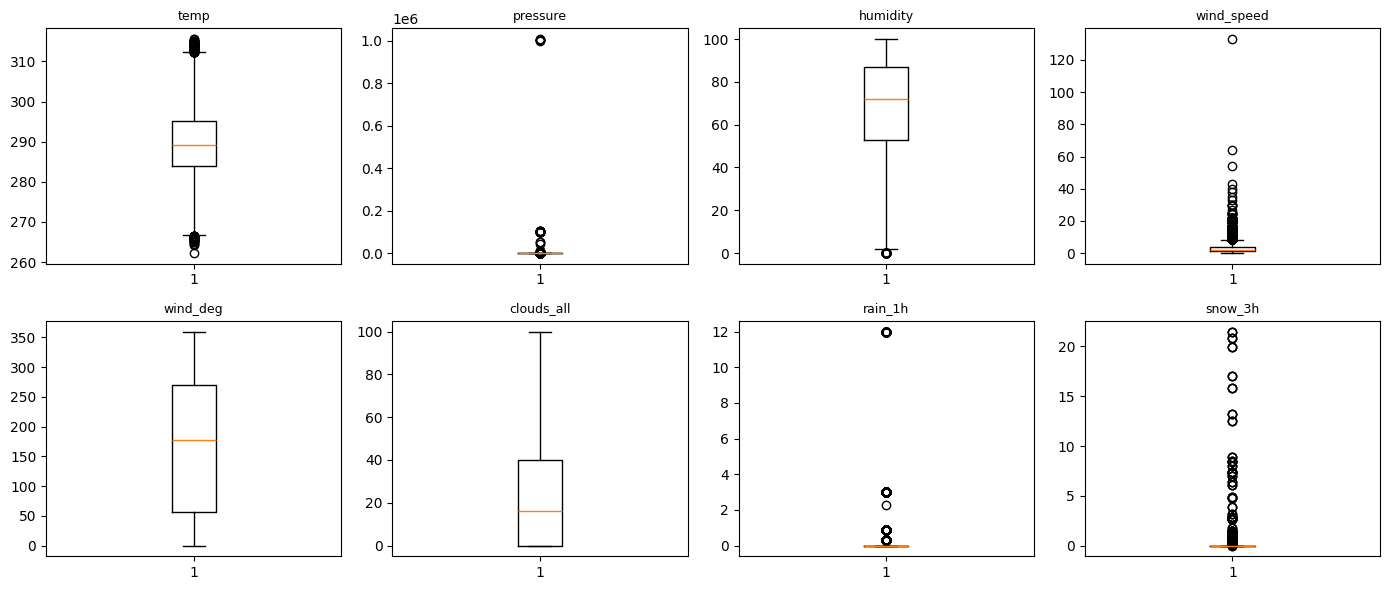

In [20]:
wcols = ["temp", "pressure", "humidity", "wind_speed",
         "wind_deg", "clouds_all", "rain_1h", "snow_3h"]

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.flat, wcols):
    ax.boxplot(wd[c])
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

## Min and Max: Energy

In [21]:
energy_num = energy.select_dtypes("number").dropna(axis=1, how="all")
energy_num.agg(["min", "max"]).T

,min,max
generation biomass,0.00,592.00
generation fossil brown coal/lignite,0.00,999.00
generation fossil coal-derived gas,0.00,0.00
generation fossil gas,0.00,20034.00
generation fossil hard coal,0.00,8359.00
generation fossil oil,0.00,449.00
generation fossil oil shale,0.00,0.00
generation fossil peat,0.00,0.00
generation geothermal,0.00,0.00
generation hydro pumped storage consumption,0.00,4523.00


## Min and Max: Weather

In [22]:
num_cols = ["temp", "temp_min", "temp_max", "pressure", "humidity", "wind_speed",
            "wind_deg", "rain_1h", "rain_3h", "snow_3h", "clouds_all"]
wd[num_cols].agg(["min", "max"]).T

,min,max
temp,262.24,315.600
temp_min,262.24,315.150
temp_max,262.24,321.150
pressure,0.00,1008371.000
humidity,0.00,100.000
wind_speed,0.00,133.000
wind_deg,0.00,360.000
rain_1h,0.00,12.000
rain_3h,0.00,2.315
snow_3h,0.00,21.500


## How Many Impossible Readings?

In [23]:
# Limits based on known ranges:
# pressure: normal sea-level pressure is roughly 900-1100 hPa
# wind: Beaufort scale, force 11 (violent storm) starts at 28.5 m/s
PRESSURE_MIN, PRESSURE_MAX = 900, 1100
WIND_LIMIT = 28.5

checks = {
    f"pressure outside {PRESSURE_MIN}-{PRESSURE_MAX}": (wd["pressure"] < PRESSURE_MIN) | (wd["pressure"] > PRESSURE_MAX),
    f"wind_speed >= {WIND_LIMIT} (Beaufort 11+)": wd["wind_speed"] >= WIND_LIMIT,
    "humidity = 0": wd["humidity"] == 0,
}
for name, mask in checks.items():
    print(name, "| rows:", mask.sum(), "|", wd[mask]["city_name"].value_counts().to_dict())

pressure outside 900-1100 | rows: 48 | {' Barcelona': 48}
wind_speed >= 28.5 (Beaufort 11+) | rows: 12 | {'Valencia': 12}
humidity = 0 | rows: 63 | {' Barcelona': 61, 'Madrid': 2}


## Wind Speed by Beaufort Class

In [24]:
bins = [0, 24.5, 28.5, 32.7, float("inf")]
labels = ["below storm", "storm (force 10)", "violent storm (force 11)", "hurricane force (force 12)"]

pd.cut(wd["wind_speed"], bins=bins, labels=labels, right=False).value_counts().sort_index()

wind_speed
below storm                   175304
storm (force 10)                   4
violent storm (force 11)           4
hurricane force (force 12)         8
Name: count, dtype: int64

## Zeros in Gas and Nuclear

In [25]:
# Check zeros in generation columns where zero is unexpected:
# - fossil gas and nuclear usually run continuously, so a value of 0 is suspicious
# - (solar at night or low wind can be 0 normally, so we do not check them here)

for c in ["generation fossil gas", "generation nuclear"]:
    z = energy[c] == 0                          # True for hours where the value is exactly 0
    print(c, "| zero hours:", z.sum())          # how many hours have zero
    print(energy.index[z][:10])                 # dates of the first 10 zero hours

generation fossil gas | zero hours: 1
DatetimeIndex(['2018-06-02 09:00:00+00:00'], dtype='datetime64[ns, UTC]', name='time', freq=None)
generation nuclear | zero hours: 3
DatetimeIndex(['2017-11-12 20:00:00+00:00', '2017-11-14 11:00:00+00:00',
               '2017-11-14 18:00:00+00:00'],
              dtype='datetime64[ns, UTC]', name='time', freq=None)


# Step 4: Sudden changes in units, sensors, or data collection.


## When Do the Suspicious Weather Values Happen?

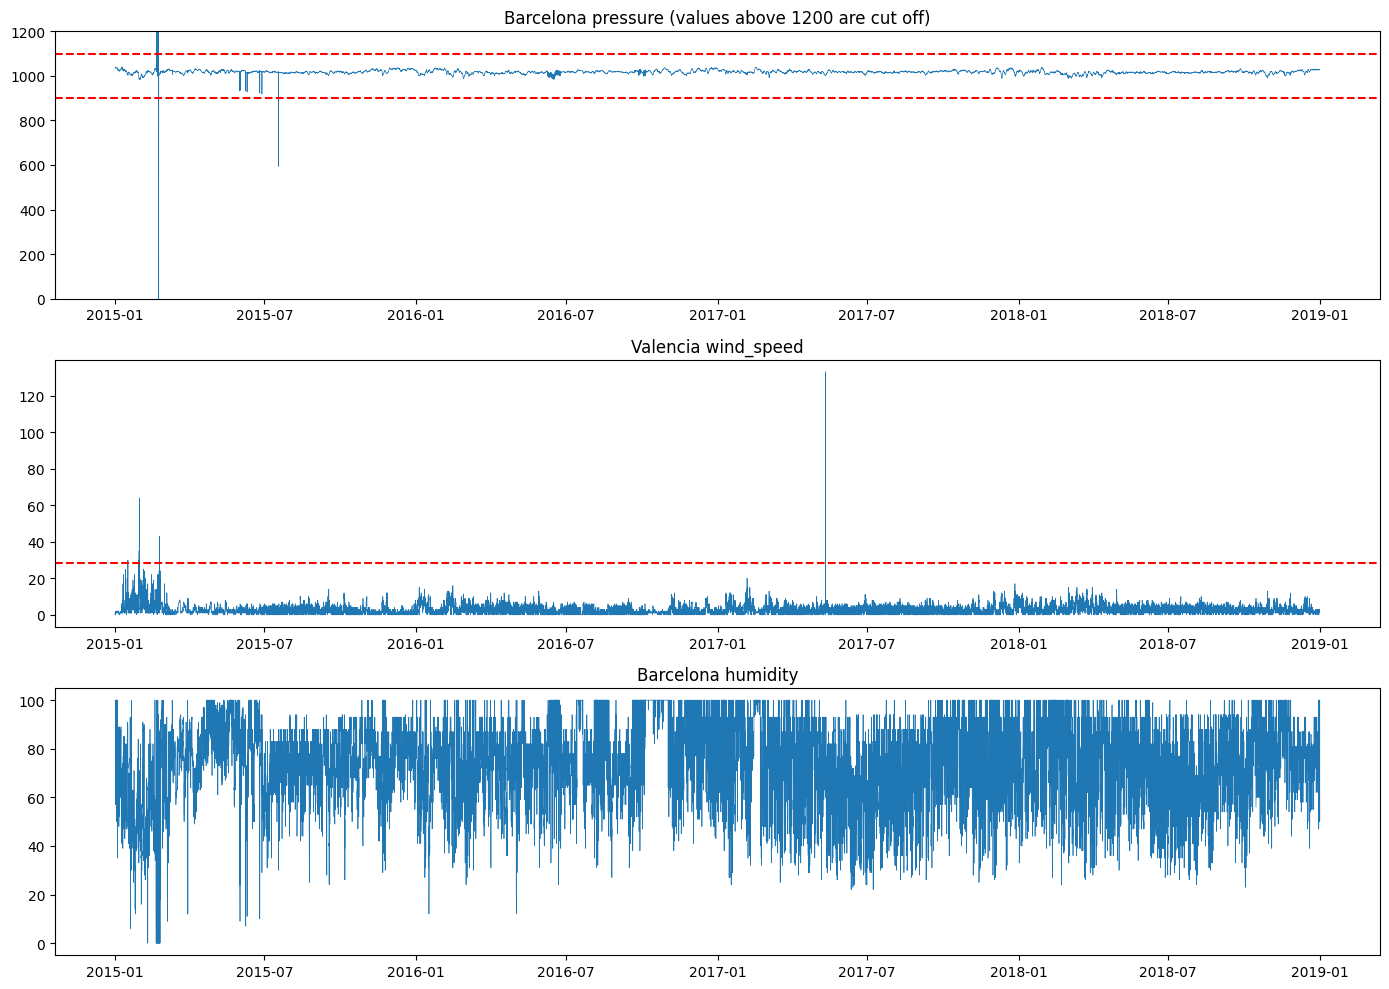

In [27]:
import matplotlib.pyplot as plt

def city_series(city, col):
    return wd[wd["city_name"] == city].set_index("dt_iso").sort_index()[col]

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

p = city_series(" Barcelona", "pressure")          # لاحظي المسافة قبل Barcelona
axes[0].plot(p.index, p.values, lw=0.5)
axes[0].axhline(900, color="red", ls="--"); axes[0].axhline(1100, color="red", ls="--")
axes[0].set_ylim(0, 1200); axes[0].set_title("Barcelona pressure (values above 1200 are cut off)")

w = city_series("Valencia", "wind_speed")
axes[1].plot(w.index, w.values, lw=0.5)
axes[1].axhline(28.5, color="red", ls="--"); axes[1].set_title("Valencia wind_speed")

h = city_series(" Barcelona", "humidity")
axes[2].plot(h.index, h.values, lw=0.5); axes[2].set_title("Barcelona humidity")

plt.tight_layout(); plt.show()

## Isolated Hours or Lasting?

In [28]:
def runs_for(city, col, is_bad):
    s = wd[wd["city_name"] == city].set_index("dt_iso").sort_index()[col]
    return find_gaps(s.where(~is_bad(s)))     # bad hours become NaN, then same gap function

p_runs = runs_for(" Barcelona", "pressure", lambda s: (s < 900) | (s > 1100))
w_runs = runs_for("Valencia", "wind_speed", lambda s: s >= 28.5)
h_runs = runs_for(" Barcelona", "humidity", lambda s: s == 0)

for name, r in [("pressure", p_runs), ("wind_speed", w_runs), ("humidity", h_runs)]:
    print(name, "| groups:", len(r))
    print(r["hours"].value_counts().sort_index().to_dict())
    print()
p_runs

pressure | groups: 9
{1: 2, 2: 1, 3: 1, 4: 1, 8: 1, 9: 2, 11: 1}

wind_speed | groups: 8
{1: 4, 2: 4}

humidity | groups: 13
{1: 6, 2: 1, 4: 1, 5: 1, 6: 1, 8: 1, 14: 1, 16: 1}



,start,end,hours
pressure,,,
2,2015-02-20 08:00:00+00:00,2015-02-20 15:00:00+00:00,8
4,2015-02-20 17:00:00+00:00,2015-02-21 01:00:00+00:00,9
6,2015-02-21 04:00:00+00:00,2015-02-21 14:00:00+00:00,11
8,2015-02-21 16:00:00+00:00,2015-02-21 18:00:00+00:00,3
10,2015-02-21 21:00:00+00:00,2015-02-22 00:00:00+00:00,4
12,2015-02-22 03:00:00+00:00,2015-02-22 11:00:00+00:00,9
14,2015-02-22 13:00:00+00:00,2015-02-22 13:00:00+00:00,1
16,2015-02-22 19:00:00+00:00,2015-02-22 20:00:00+00:00,2
18,2015-07-18 02:00:00+00:00,2015-07-18 02:00:00+00:00,1


## 30-Day Rolling Average

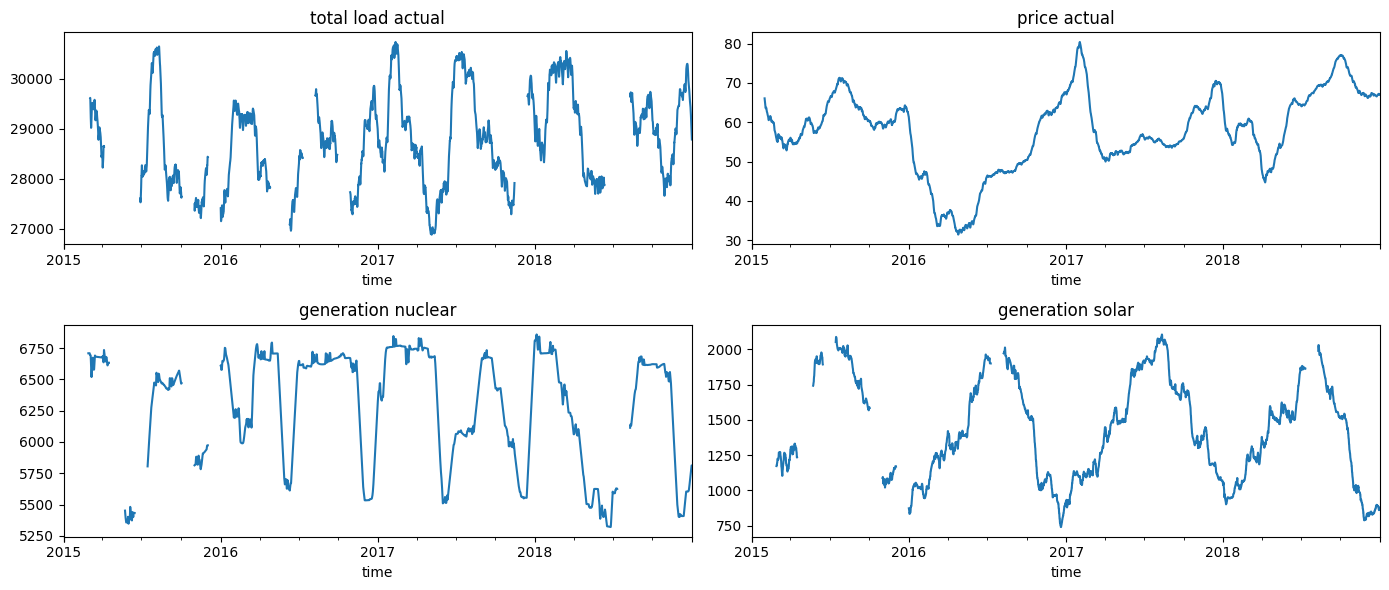

In [29]:
cols = ["total load actual", "price actual", "generation nuclear", "generation solar"]
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for ax, c in zip(axes.flat, cols):
    energy[c].rolling(24 * 30).mean().plot(ax=ax, title=c)
plt.tight_layout()
plt.show()

## Price Spikes: Isolated or Lasting?

In [30]:
p = energy["price actual"]
spike_runs = find_gaps(p.where(p <= p.quantile(0.99)))
print(spike_runs["hours"].value_counts().sort_index())
spike_runs.sort_values("hours", ascending=False).head(10)

hours
1     22
2     17
3     20
4     12
5      7
6      2
7      2
16     1
17     1
18     3
19     1
20     1
Name: count, dtype: int64


,start,end,hours
price actual,,,
130,2017-01-25 06:00:00+00:00,2017-01-26 01:00:00+00:00,20
128,2017-01-24 06:00:00+00:00,2017-01-25 00:00:00+00:00,19
116,2017-01-19 06:00:00+00:00,2017-01-19 23:00:00+00:00,18
118,2017-01-20 06:00:00+00:00,2017-01-20 23:00:00+00:00,18
126,2017-01-23 06:00:00+00:00,2017-01-23 23:00:00+00:00,18
132,2017-01-26 06:00:00+00:00,2017-01-26 22:00:00+00:00,17
114,2017-01-18 07:00:00+00:00,2017-01-18 22:00:00+00:00,16
122,2017-01-21 17:00:00+00:00,2017-01-21 23:00:00+00:00,7
96,2017-01-12 07:00:00+00:00,2017-01-12 13:00:00+00:00,7


## Sudden One-Hour Jumps (local median check)

**Why this check:** the zero check and min/max miss faults that do not drop to zero. Example: on 2018-05-06 10:00, nuclear is 998 while its neighbors are about 4,057, and demand drops to 19,964 for one hour and then recovers. The yearly means and the 30-day rolling plots also hide one-hour faults.

**Idea:** compare each hour with the **median of its neighbors** (3 hours before and 3 after). The median is used because one bad reading does not distort it.

**A logging fault usually hits several columns at the same hour, while a real event usually changes one column.** So we use two levels: a per-column report (wide list), and hours where 2 or more columns jump together (strongest suspects).

These cells only **flag** hours. They do not change or delete anything.

In [31]:
def jump_ratio(series, window=7):
    # relative distance of each hour from the median of its neighbors
    med = series.rolling(window, center=True, min_periods=3).median()
    med = med.where(med > 0)            # avoid division by zero when the local median is 0
    return (series - med).abs() / med

# 1) Nuclear first: it is very stable in this data, so jumps stand out
nuc_dev = jump_ratio(energy["generation nuclear"])
nuc_flag = energy.loc[nuc_dev > 0.15, ["generation nuclear", "total load actual"]].copy()
nuc_flag["relative_jump"] = nuc_dev[nuc_flag.index].round(2)
print("Hours flagged (nuclear, threshold 15%):", len(nuc_flag))
nuc_flag

Hours flagged (nuclear, threshold 15%): 8


,generation nuclear,total load actual,relative_jump
time,,,
2015-01-04 23:00:00+00:00,4036.0,25069.0,0.27
2015-05-31 20:00:00+00:00,4367.0,27282.0,0.16
2015-08-26 17:00:00+00:00,3939.0,18616.0,0.41
2017-11-12 20:00:00+00:00,0.0,36562.0,1.00
2017-11-12 22:00:00+00:00,7092.0,30529.0,0.40
2017-11-14 11:00:00+00:00,0.0,NaN,1.00
2017-11-14 18:00:00+00:00,0.0,NaN,1.00
2018-05-06 10:00:00+00:00,998.0,19964.0,0.75


In [32]:
# 2) Several columns: how many hours does each threshold flag, per column?
cols_check = ["generation nuclear", "generation fossil gas",
              "generation fossil hard coal", "total load actual"]
thresholds = [0.15, 0.3, 0.5]

devs = pd.DataFrame({c: jump_ratio(energy[c]) for c in cols_check})
report = pd.DataFrame({f"> {int(t * 100)}%": (devs > t).sum() for t in thresholds})
report

,> 15%,> 30%,> 50%
generation nuclear,8,6,4
generation fossil gas,484,39,3
generation fossil hard coal,403,31,10
total load actual,7,3,0


# Step 5 : Whether the time interval stays regular across the full dataset.


## Time Interval Regularity

In [33]:
# Time interval between consecutive rows (should be exactly 1 hour everywhere)
print("Energy:")
print(energy.index.to_series().diff().value_counts())

print("\nWeather (per city, after temporary de-duplication):")
for city, g in wd.groupby("city_name"):
    diffs = g.sort_values("dt_iso")["dt_iso"].diff().value_counts().to_dict()
    print(city, diffs)

Energy:
time
0 days 01:00:00    35063
Name: count, dtype: int64

Weather (per city, after temporary de-duplication):
 Barcelona {Timedelta('0 days 01:00:00'): 35063}
Bilbao {Timedelta('0 days 01:00:00'): 35063}
Madrid {Timedelta('0 days 01:00:00'): 35063}
Seville {Timedelta('0 days 01:00:00'): 35063}
Valencia {Timedelta('0 days 01:00:00'): 35063}
